*Note: This lab will be due after the exam, on October 14 @ midnight.*

## A/B Testing, Randomized Controlled Trials

- We want to estimate the **average treatment effect**: The average difference in outcomes between the treatment and control groups
- Remember, the stakes are something like: If we implement this intervention at the scale of millions of patients, how many lives are:
    - Saved because the treatment works and our experiment showed it did (Good)
    - Not lost because the treatment doesn't work and our experiment showed it doesn't work (Good)
    - Not saved because the treatment works but our experiment failed to show it did (Bad)
    - Lost because the treatment actually harms patients, but our experiment falsely suggested it works (Very bad)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

We generally can't compare what would have happened to observation $i$, if they had been assigned to the other treatment. This means we only observe
$$
y_{iA} = \text{Outcome for $i$ receiving treatment $A$ }
$$
or
$$
y_{iB} = \text{Outcome for $i$ receiving treatment $B$ }
$$
but not both. The **average outcome** for group $A$ is
$$
\frac{1}{\text{Size of group } A} \sum_{i \text{ receiving } A} y_{iA}
$$
and the **average outcome** for group $B$ is
$$
\frac{1}{\text{Size of group } B} \sum_{i \text{ receiving } B} y_{iB}.
$$
When we difference them, we get the **Average Treatment Effect (ATE)**:
$$
ATE = \dfrac{1}{\text{Size of group } A} \sum_{i \text{ receiving } A} y_{iA} \quad - \quad \frac{1}{\text{Size of group } B} \sum_{i \text{ receiving } B} y_{iB}
$$
As long as treatment is randomly assigned, there is no reason to think that the participants in group $A$ or $B$ are systematically different, and the **ATE** is an unbiased estimator of the true contrast in outcomes between groups $B$ and $A$. We "average away" the differences across the two groups to get an estimate of the difference in outcomes.

We then use bootstrapping to do two things:

1. Estimate the density/distribution for the averages outcomes in both groups
2. Estimate the ATE and its density/distribution

## Part 1

- First, we're going to evaluate a particular clinical trial, on chronic kidney disease:
    - ISCHEMIA-Chronic Kidney Disease Trial (ISCHEMIA-CKD)
    - ClinicalTrials.gov ID NCT01985360
    - Sponsor NYU Langone Health
    - Information provided by NYU Langone Health (Responsible Party)
- The study compared a "routine invasive therapy" (intra-aortic balloon pumps) intended to reduce death/heart attack versus more conservative medical interventions during heart surgery

<img src="./src/Intraaortic_Balloon.png" width=600>

<div>
<img src="./src/ischemia.png" width="700"/>
</div>

**1.** Load the `./data/iabp.csv` data. Cross tabulate `Group` and `Survived`. What is the point estimate of the ATE? Would you rather get the intra aortic balloon pump or not? Remember, A means pump and B means not.

In [2]:
df = pd.read_csv('../data/iabp.csv')

## Crosstabs, average treatment effect:
print(pd.crosstab( df['Group'], df['Survived']), '\n')

ate = df.loc[ df['Group'] == 'Invasive', 'Survived'].mean() \
    - df.loc[ df['Group'] == 'Conservative', 'Survived'].mean() 
print('Estimated ATE: ', np.round(ate, 3))

Survived      0.0  1.0
Group                 
Conservative  290   99
Invasive      293   95 

Estimated ATE:  -0.01


**The point estimate of the ATE is -0.01. I personally would rather get the conservative treatment, as the ATE is only -0.01, and the difference in the 2 groups is marginal. With a difference of 1 percentage point, I would choose the less stressful procedure. However, this alone is not conclusive at all and the bootstrapping is necessary to get more confidence in the treatment effect.**

**2.** Bootstrap the average outcome for group A, the average outcome for group B, and difference then to get the ATE, 10,000 times. Store all of these estimates. This is very important: **Bootstrap the two groups separately, since this is a clinical trial and there was random assignment (we want to maintain the balance across treatment arms).

In [3]:
## Bootstrapping:
R = 10_000

df_a = df.loc[ df['Group'] == 'Invasive',:]
df_b = df.loc[ df['Group'] == 'Conservative',:]

outcome_a = []
outcome_b = []
ate = [] # Store computed effects

for t in range(R):
    #df_t = df.sample( df.shape[0], axis=0, replace=True) # Resample

    df_at = df_a.sample(frac=1.0, replace=True)
    df_bt = df_b.sample(frac=1.0, replace=True)

    oat = df_at['Survived'].mean() # Mean outcome for A
    obt = df_bt['Survived'].mean() # Mean outcome for B    
    ate_t = oat - obt # Compute ATE for this bootstrap sample

    outcome_a.append(oat) # Save new value
    outcome_b.append(obt) # Save new value
    ate.append(ate_t) # Save new value

**3.** Make a plot of the KDEs of the outcomes for the two groups, and a plot of the ECDFs for the two groups. What relationships do you see between the two groups?

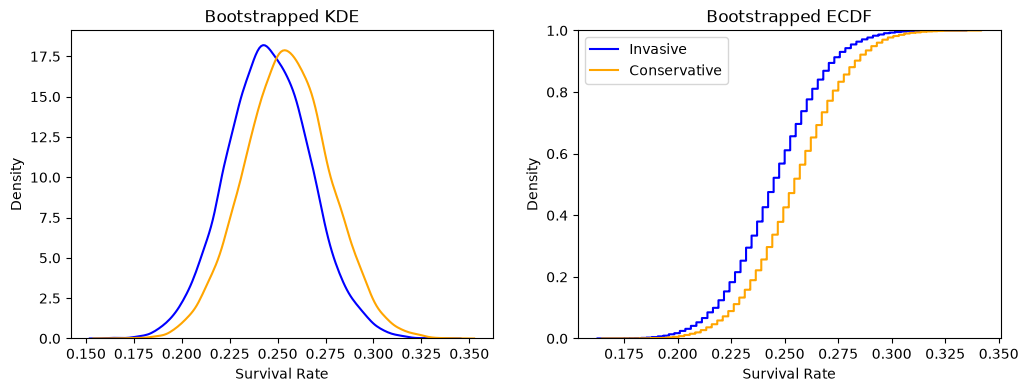

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

sns.kdeplot(outcome_a, label='Invasive', color='blue', ax=ax[0])
sns.kdeplot(outcome_b, label='Conservative', color='orange', ax=ax[0]).set(title='Bootstrapped KDE', xlabel='Survival Rate', ylabel='Density')

sns.ecdfplot(outcome_a, label='Invasive', color='blue', ax=ax[1])
sns.ecdfplot(outcome_b, label='Conservative', color='orange', ax=ax[1]).set(title='Bootstrapped ECDF', xlabel='Survival Rate', ylabel='Density')

plt.legend()
plt.show()

**After the bootstrapping, in the KDEs, the density for the conservative procedure was similar to the invasive procedure, although the density of the conservative plot peaked slightly higher. Similarly, the ECDF shows that the curve for the invasive procedure is nestled above the curve for the conservative procedure at most points. Overall, these plots indicate that in this study, the survival rate for patients who had the conservative procedure may be marginally higher.**

**4.** Make a plot of the KDE and ECDF for the ATE. 

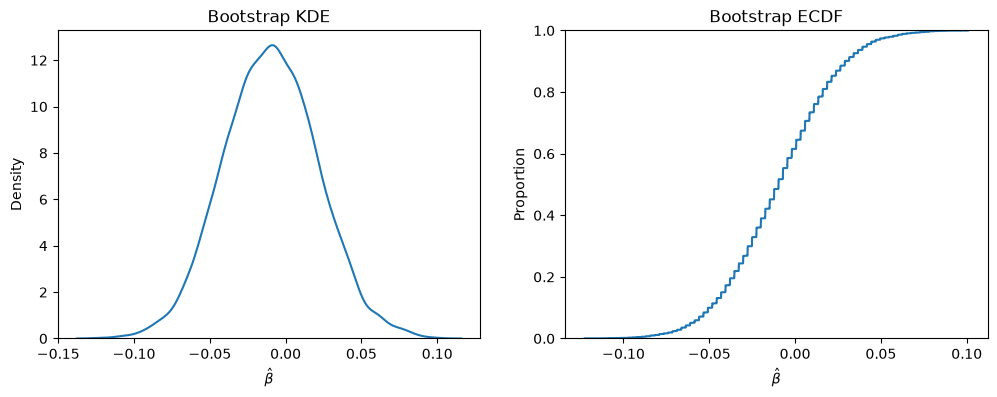

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

## KDE
sns.kdeplot(ate, ax=ax[0])
ax[0].set_xlabel(r"$\hat{\beta}$")
ax[0].set_title("Bootstrap KDE")

## ECDF
sns.ecdfplot(ate, ax=ax[1])
ax[1].set_xlabel(r"$\hat{\beta}$")
ax[1].set_title("Bootstrap ECDF")

plt.show()


**5.** Compute 90%, 95%, and 99% confidence intervals for the ATE. Is zero in those intervals? For which do we "fail to reject the null hypothesis that the effect size is zero" and for which do we "reject the null hypothesis that the effect size is zero"?

In [6]:
ci90 = np.quantile(ate, [.05, .95])
ci95 = np.quantile(ate, [.025, .975])
ci99 = np.quantile(ate, [.005, .995])

print(f"90% CI: {ci90}")
print(f"95% CI: {ci95}")
print(f"99% CI: {ci99}")

90% CI: [-0.06106757  0.04181386]
95% CI: [-0.06888549  0.0521031 ]
99% CI: [-0.08945757  0.07521934]


**Yes, each interval includes 0. We fail to reject the null hypothesis that the effect size is 0 at all 3 significance levels. This shows that in this study, there is no evidence indicating that 1 treatment option is more or less effective than the other.**

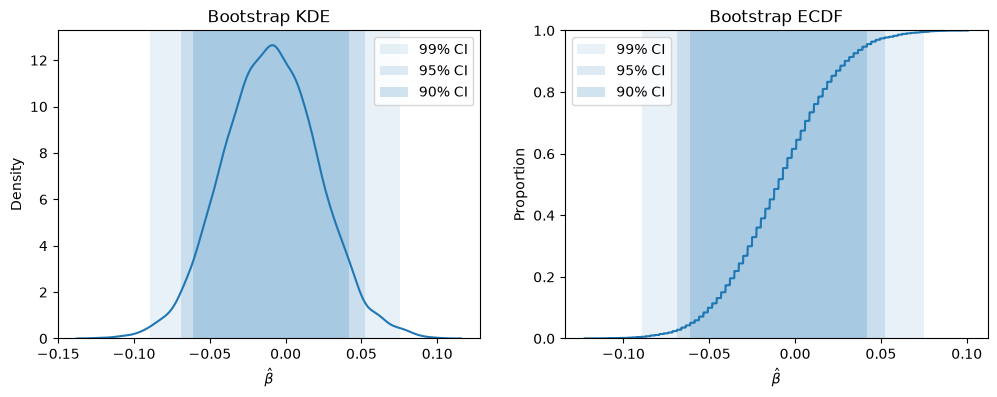

In [7]:
# Percentile bootstrap confidence intervals
ci90 = np.quantile(ate, [.05, .95])
ci95 = np.quantile(ate, [.025, .975])
ci99 = np.quantile(ate, [.005, .995])

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

## KDE
sns.kdeplot(ate, ax=ax[0])

ax[0].axvspan(ci99[0], ci99[1], alpha=0.10, label="99% CI")
ax[0].axvspan(ci95[0], ci95[1], alpha=0.15, label="95% CI")
ax[0].axvspan(ci90[0], ci90[1], alpha=0.20, label="90% CI")

ax[0].set_xlabel(r"$\hat{\beta}$")
ax[0].set_title("Bootstrap KDE")
ax[0].legend()

## ECDF
sns.ecdfplot(ate, ax=ax[1])

ax[1].axvspan(ci99[0], ci99[1], alpha=0.10, label="99% CI")
ax[1].axvspan(ci95[0], ci95[1], alpha=0.15, label="95% CI")
ax[1].axvspan(ci90[0], ci90[1], alpha=0.20, label="90% CI")

ax[1].set_xlabel(r"$\hat{\beta}$")
ax[1].set_title("Bootstrap ECDF")
ax[1].legend()

**6.** What have we learned about inserting balloons into hearts?

**We have learned that at least in this study, there is not statistically significant evidence that inserting balloons into hearts is more or less effective than a more conservative treatment approach.**

# Part 2

In `./data/diabetes.csv`, there is data from a clinical trial considering three treatments for pre-diabetics to reduce the progression to full diabetes: metformin, rosiglitazone, and lifestyle adjustments (diet, exercise). Unlike Part 1, there aren't two treatment arms (i.e. A = aortic balloon, B = no aortic balloon), but three (met, rosi, lifestyle).

You are a data analyst working for `clinicaltrials.gov` and the FDA to provide an unbiased review of the trial's results. The researchers have provided you with `./data/diabests.csv`.

In an ipynb or py file:

1. Load the `./data/diabetes.csv` data. Cross tabulate the outcomes for the three groups. What are the average outcomes for the three groups? 
2. Bootstrap the outcomes for the three groups 10,000 times. Store all of these estimates. As this is another randomized controlled trial, do the resampling within the arms. 
3. Plot the three densities on one plot and three distributions on another. Describe any patterns you see.
4. There are three treatment effects: met versus rosi, met versus lifestyle, rosi versus lifestyle. Make KDE and ECDF plots of all these comparisons.
5. Compute confidence intervals for each pairwise ATE based on its ECDF (percentile bootstrap). Do you find any statistically significant differences between the interventions? Which seems the most effective?

Then:

6. Write a short report (3-5 paragraphs) that summarizes the evidence from the trial for adopting each of the interventions or not. Use tables and visualizations. Write in a professional tone for a technical audience, and focus on evidence (or the lack thereof). Do not assume anyone has read your work in your notebooks.

**1.**

In [27]:
df = pd.read_csv('../data/diabetes.csv')
df['outcome'] = df['outcome'].str.contains('success', case=False, na=False).astype(int)

## Crosstabs, average treatment effect:
print(pd.crosstab( df['treatment'], df['outcome']), '\n')
means = df.groupby('treatment')['outcome'].mean()

print('\nEstimated ATEs:')
print('met vs. rosi: ', means['met'] - means['rosi'])
print('met vs. lifestyle: ', means['met'] - means['lifestyle'])
print('rosi vs. lifestyle: ', means['rosi'] - means['lifestyle'])


print('\nMEANS:')
means

outcome      0    1
treatment          
lifestyle  109  125
met        120  112
rosi        90  143 


Estimated ATEs:
met vs. rosi:  -0.13097528488974391
met vs. lifestyle:  -0.051429413498378984
rosi vs. lifestyle:  0.07954587139136493

MEANS:


treatment
lifestyle    0.534188
met          0.482759
rosi         0.613734
Name: outcome, dtype: float64

**2.**

In [28]:
## Bootstrapping:
R = 10_000

df_a = df.loc[ df['treatment'] == 'lifestyle',:]
df_b = df.loc[ df['treatment'] == 'met',:]
df_c = df.loc[ df['treatment'] == 'rosi',:]


outcome_a = []
outcome_b = []
outcome_c = []
ate_mr = [] # met vs. rosi
ate_ml = [] # met vs. lifestyle
ate_rl = [] # rosi vs. lifestyle

for t in range(R):
    #df_t = df.sample( df.shape[0], axis=0, replace=True) # Resample

    df_at = df_a.sample(frac=1.0, replace=True)
    df_bt = df_b.sample(frac=1.0, replace=True)
    df_ct = df_c.sample(frac=1.0, replace=True)


    oat = df_at['outcome'].mean() # Mean outcome for A
    obt = df_bt['outcome'].mean() # Mean outcome for B    
    oct = df_ct['outcome'].mean() # Mean outcome for C  

    ate_t_mr = obt - oct #met vs. rosi
    ate_t_ml = obt - oat #met vs. lifestyle
    ate_t_rl = oct - oat #rosi vs. lifestyle


    outcome_a.append(oat) # Save new value
    outcome_b.append(obt) # Save new value
    outcome_c.append(oct)
    ate_mr.append(ate_t_mr) # Save new value
    ate_ml.append(ate_t_ml)
    ate_rl.append(ate_t_rl)

**3.**

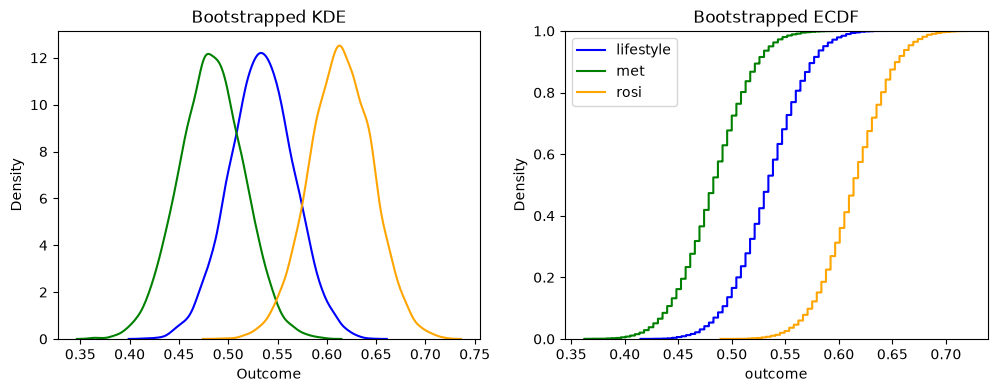

In [29]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

sns.kdeplot(outcome_a, label='lifestyle', color='blue', ax=ax[0])
sns.kdeplot(outcome_b, label='met', color='green', ax=ax[0])
sns.kdeplot(outcome_c, label='rosi', color='orange', ax=ax[0]).set(title='Bootstrapped KDE', xlabel='Outcome', ylabel='Density')

sns.ecdfplot(outcome_a, label='lifestyle', color='blue', ax=ax[1])
sns.ecdfplot(outcome_b, label='met', color='green', ax=ax[1])
sns.ecdfplot(outcome_c, label='rosi', color='orange', ax=ax[1]).set(title='Bootstrapped ECDF', xlabel='outcome', ylabel='Density')

plt.legend()
plt.show()

**The 3 treatment options form distinct groups in both plots. In the KDEs, the density curve for lifestyle is situated in between the curves for met and rosi. Rosi has the rightmost curve. In the ECDFs, rosi also has the rightmost curve. At this stage, these plots suggest that rosi may be more effective than the other 2 treatment options.**

**4.**

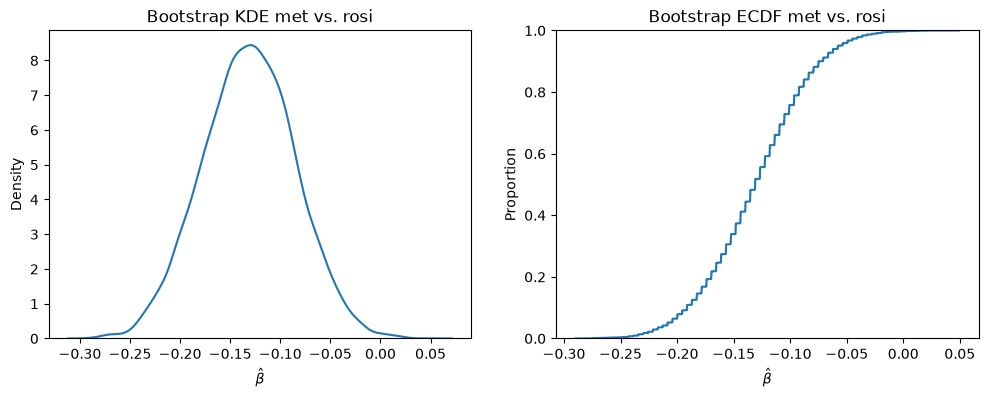

In [30]:
## met vs. rosi
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

## KDE
sns.kdeplot(ate_mr, ax=ax[0])
ax[0].set_xlabel(r"$\hat{\beta}$")
ax[0].set_title("Bootstrap KDE met vs. rosi")

## ECDF
sns.ecdfplot(ate_mr, ax=ax[1])
ax[1].set_xlabel(r"$\hat{\beta}$")
ax[1].set_title("Bootstrap ECDF met vs. rosi")

plt.show()


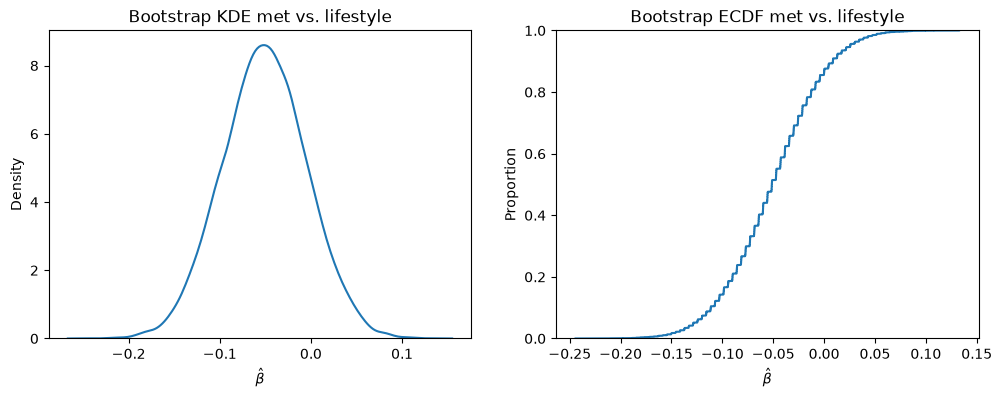

In [31]:

## met vs. lifestyle
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

## KDE
sns.kdeplot(ate_ml, ax=ax[0])
ax[0].set_xlabel(r"$\hat{\beta}$")
ax[0].set_title("Bootstrap KDE met vs. lifestyle")

## ECDF
sns.ecdfplot(ate_ml, ax=ax[1])
ax[1].set_xlabel(r"$\hat{\beta}$")
ax[1].set_title("Bootstrap ECDF met vs. lifestyle")

plt.show()


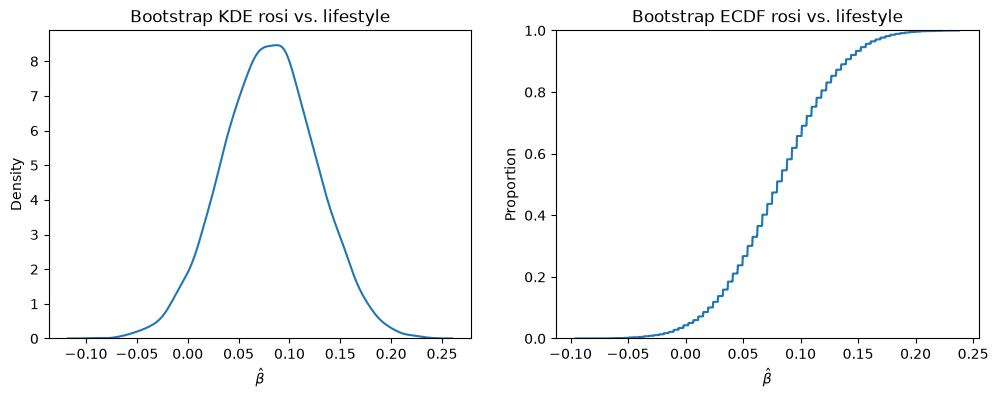

In [32]:

## rosi vs. lifestyle
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

## KDE
sns.kdeplot(ate_rl, ax=ax[0])
ax[0].set_xlabel(r"$\hat{\beta}$")
ax[0].set_title("Bootstrap KDE rosi vs. lifestyle")

## ECDF
sns.ecdfplot(ate_rl, ax=ax[1])
ax[1].set_xlabel(r"$\hat{\beta}$")
ax[1].set_title("Bootstrap ECDF rosi vs. lifestyle")

plt.show()

**5.**

In [33]:
## met vs. rosi
ci90 = np.quantile(ate_mr, [.05, .95])
ci95 = np.quantile(ate_mr, [.025, .975])
ci99 = np.quantile(ate_mr, [.005, .995])

print(f"90% CI: {ci90}")
print(f"95% CI: {ci95}")
print(f"99% CI: {ci99}")

90% CI: [-0.208284   -0.05773642]
95% CI: [-0.22132603 -0.04071703]
99% CI: [-0.2469477  -0.01485497]


In [34]:
## met vs. lifestyle
ci90 = np.quantile(ate_ml, [.05, .95])
ci95 = np.quantile(ate_ml, [.025, .975])
ci99 = np.quantile(ate_ml, [.005, .995])

print(f"90% CI: {ci90}")
print(f"95% CI: {ci95}")
print(f"99% CI: {ci99}")

90% CI: [-0.12853669  0.02571471]
95% CI: [-0.14143181  0.03879402]
99% CI: [-0.17171419  0.06478448]


In [35]:
## rosi vs. lifestyle
ci90 = np.quantile(ate_rl, [.05, .95])
ci95 = np.quantile(ate_rl, [.025, .975])
ci99 = np.quantile(ate_rl, [.005, .995])

print(f"90% CI: {ci90}")
print(f"95% CI: {ci95}")
print(f"99% CI: {ci99}")

90% CI: [0.00262279 0.15661568]
95% CI: [-0.01038113  0.16950956]
99% CI: [-0.040314    0.19540846]


**There is a statistically significant difference between rosi vs. met at every interval.**
**There is also a statistically significant difference between rosi vs. lifestyle at the 90% condfidence interval. The left bound of the interval is just marginally greater than zero at 0.002, meaning that after bootstrapping, the rosi treatment showed a noticeable improvement in success when compared to the lifestyle treatment.**

**6.**

## Report

**After examining the trial, there is statistically significant evidence that rosiglitzalone is an effective treatment in comparison to metformin. First, it was noticed that the rosi treatment did have a higher rate of success compared to the other two treatments. Rosi treatment had an overall success rate of 61.4%. Lifestyle had a success rate of 53.4% and met had a success rate of 48.3%. These results are pictured in the table below. In order to verify these results, a bootstrapping simulation was performed with 10,000 replicates. The resampling was done separately within each arm, which preserved randomness.**

**During the bootstrapping process, each resample had the same number of participants as the original group. Three pairwise differences in success rate were calculated: met vs. rosi, rosi vs. lifestyle, and met vs. lifestyle. The bootstrapped distributions reinforced the pattern from the original table: rosi had the rightmost kde density curve, and had an ECDF curve located to the right of the met and lifestyle curves.**

**The most significant results were the bootstrapped confidence intervals, which are pictured below. The statistically significant intervals are highlighted in green. There was no statistically significant evidence that metformin is more or less effective than lifestyle changes. As seen below, rosi was a more effective treatment when compared to met at all 3 intervals. Because the differences are calculated as the second treatment subtracted from the first treatment, the fully negative intervals in that row indicate this. There was also a statistically significant between rosi and lifestyle at the 90% interval. However, because this pattern only occured at the 90% interval, it is difficult to conclude that there was a significant difference between rosi and lifestyle. Overall, the study shows that rosiglitzalone was significantly more effective at treating diabetes when compared to metformin, and that there was not enough evidence to support significant differences in success between metformin and lifestyle and rosi and lifestyle.**

In [40]:
## Average outcome (success rate) by treatment
means_table = df.groupby('treatment')['outcome'].mean().round(3).to_frame('success rate')

means_table

,success rate
treatment,
lifestyle,0.534
met,0.483
rosi,0.614


In [39]:
ci_table = pd.DataFrame({
    '90% CI': [np.quantile(ate_mr, [.05, .95]).round(3),
               np.quantile(ate_ml, [.05, .95]).round(3),
               np.quantile(ate_rl, [.05, .95]).round(3)],
    '95% CI': [np.quantile(ate_mr, [.025, .975]).round(3),
               np.quantile(ate_ml, [.025, .975]).round(3),
               np.quantile(ate_rl, [.025, .975]).round(3)],
    '99% CI': [np.quantile(ate_mr, [.005, .995]).round(3),
               np.quantile(ate_ml, [.005, .995]).round(3),
               np.quantile(ate_rl, [.005, .995]).round(3)],
}, index=['met vs. rosi', 'met vs. lifestyle', 'rosi vs. lifestyle'])

def highlight_significant(ci):
    if ci[0] > 0 or ci[1] < 0:
        return 'background-color: green'
    return ''

ci_table.style.map(highlight_significant)

,90% CI,95% CI,99% CI
met vs. rosi,[-0.208 -0.058],[-0.221 -0.041],[-0.247 -0.015]
met vs. lifestyle,[-0.129 0.026],[-0.141 0.039],[-0.172 0.065]
rosi vs. lifestyle,[0.003 0.157],[-0.01 0.17],[-0.04 0.195]
